# Underfitting, Overfitting and Regularisation

We have a training set with two classes. We want a model that draws the boundary between them.

We train three models that differ only in size, look at the boundary each one draws, and read the training and validation loss curves. Then we take the worst of the three and try to repair it with L2, L1 and dropout.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import keras
from sklearn.datasets import make_moons
from matplotlib.colors import LinearSegmentedColormap, ListedColormap

In [ ]:
# colours used by every plot below
BLUE = "#1C7ED6"
ORANGE = "#F76707"
GREEN = "#2F9E44"
PURPLE = "#AE3EC9"

# pale background for the boundary plots, and the two point colours
BACKGROUND = LinearSegmentedColormap.from_list("bg", ["#FFE0CC", "#FFFFFF", "#CFE8FF"])
POINTS = ListedColormap([ORANGE, BLUE])

## The data

150 points for training, 2000 points held back for validation. The model only ever computes gradients on the 150.

In [ ]:
X, y = make_moons(n_samples=2150, noise=0.3, random_state=0)

Xtr, ytr = X[:150], y[:150]
Xva, yva = X[150:], y[150:]

print("training set", Xtr.shape)
print("validation set", Xva.shape)

training set (150, 2)
validation set (2000, 2)


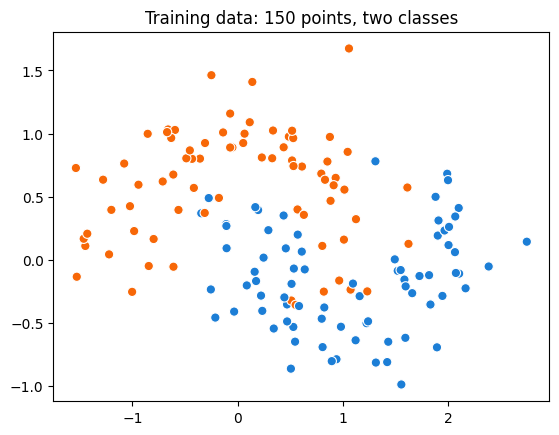

In [ ]:
plt.scatter(Xtr[:, 0], Xtr[:, 1], c=ytr, cmap=POINTS, edgecolors="white", linewidth=0.8, s=45)
plt.title("Training data: 150 points, two classes")
plt.show()

The two classes overlap. There is no boundary that separates the training points perfectly, so any model that classifies all 150 correctly has done something we do not want.

## Two helpers

One to draw the loss curves, one to draw the boundary a model has learned. The background colour is the probability the model assigns to the blue class, and the black line is where that probability is 0.5.

Each boundary is drawn twice, in two separate cells. The first shows the 150 training points the model was fitted to. The second shows 150 of the validation points the model has never seen. The boundary is the same in both, only the points change. All 2000 validation points are still used for the validation loss, the plot just draws 150 of them so it stays readable.

In [ ]:
def plot_loss(history, title, ymax=1):
    plt.plot(history.history["loss"], color=BLUE, linewidth=2, label="training")
    plt.plot(history.history["val_loss"], color=ORANGE, linewidth=2, label="validation")
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.ylim(0, ymax)
    plt.title(title)
    plt.legend()
    plt.show()

In [ ]:
def plot_boundary(model, title, validation=False):
    xx, yy = np.meshgrid(np.linspace(-2.5, 3.5, 300), np.linspace(-2.5, 3, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid, verbose=0).reshape(xx.shape)

    if validation:
        # only the first 150 validation points are drawn, so the plot is not
        # crowded. All 2000 are still used to compute the validation loss.
        points, labels, name = Xva[:150], yva[:150], "validation points"
    else:
        points, labels, name = Xtr, ytr, "training points"

    plt.contourf(xx, yy, Z, levels=50, cmap=BACKGROUND)
    plt.contour(xx, yy, Z, levels=[0.5], colors="#212529", linewidths=2)
    plt.scatter(points[:, 0], points[:, 1], c=labels, cmap=POINTS,
                edgecolors="white", linewidth=0.8, s=45)
    plt.title(title + ", " + name)
    plt.show()

Every model below is trained the same way, so we write that once too. Full batch, 400 epochs.

In [ ]:
def train(model):
    model.compile(optimizer=keras.optimizers.Adam(0.003),
                  loss="binary_crossentropy",
                  metrics=["accuracy"])
    return model.fit(Xtr, ytr,
                     validation_data=(Xva, yva),
                     epochs=400, batch_size=150, verbose=2)

---
## Model 1: one hidden layer, 4 units

In [ ]:
keras.utils.set_random_seed(0)

model1 = keras.Sequential([
    keras.layers.Input(shape=(2,)),
    keras.layers.Dense(4, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid"),
])

history1 = train(model1)

Epoch 1/400
1/1 - 2s - 2s/step - accuracy: 0.2400 - loss: 0.8443 - val_accuracy: 0.2245 - val_loss: 0.8441
Epoch 2/400
1/1 - 0s - 111ms/step - accuracy: 0.2400 - loss: 0.8408 - val_accuracy: 0.2235 - val_loss: 0.8407
Epoch 3/400
1/1 - 0s - 109ms/step - accuracy: 0.2400 - loss: 0.8373 - val_accuracy: 0.2235 - val_loss: 0.8374
Epoch 4/400
1/1 - 0s - 110ms/step - accuracy: 0.2400 - loss: 0.8339 - val_accuracy: 0.2235 - val_loss: 0.8342
Epoch 5/400
1/1 - 0s - 109ms/step - accuracy: 0.2400 - loss: 0.8306 - val_accuracy: 0.2245 - val_loss: 0.8310
Epoch 6/400
1/1 - 0s - 110ms/step - accuracy: 0.2400 - loss: 0.8274 - val_accuracy: 0.2245 - val_loss: 0.8279
Epoch 7/400
1/1 - 0s - 108ms/step - accuracy: 0.2400 - loss: 0.8242 - val_accuracy: 0.2250 - val_loss: 0.8249
Epoch 8/400
1/1 - 0s - 110ms/step - accuracy: 0.2400 - loss: 0.8210 - val_accuracy: 0.2265 - val_loss: 0.8219
Epoch 9/400
1/1 - 0s - 119ms/step - accuracy: 0.2467 - loss: 0.8180 - val_accuracy: 0.2290 - val_loss: 0.8190
Epoch 10/400


In [ ]:
print("parameters", model1.count_params())

parameters 17


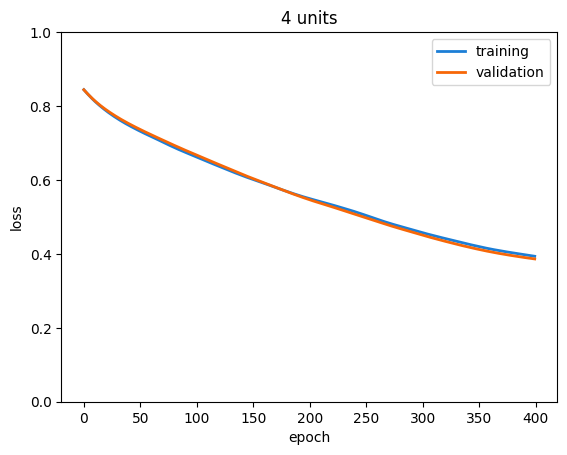

In [ ]:
plot_loss(history1, "4 units")

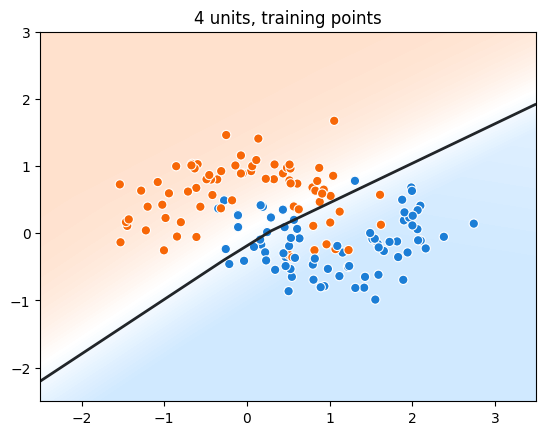

In [ ]:
plot_boundary(model1, "4 units")

## Model 2: four hidden layers, 256 units each

In [ ]:
keras.utils.set_random_seed(0)

model2 = keras.Sequential([
    keras.layers.Input(shape=(2,)),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid"),
])

history2 = train(model2)

Epoch 1/400
1/1 - 3s - 3s/step - accuracy: 0.5067 - loss: 0.6987 - val_accuracy: 0.7880 - val_loss: 0.6189
Epoch 2/400
1/1 - 0s - 174ms/step - accuracy: 0.7867 - loss: 0.6179 - val_accuracy: 0.8080 - val_loss: 0.5325
Epoch 3/400
1/1 - 0s - 119ms/step - accuracy: 0.8067 - loss: 0.5328 - val_accuracy: 0.8280 - val_loss: 0.4405
Epoch 4/400
1/1 - 0s - 117ms/step - accuracy: 0.8200 - loss: 0.4461 - val_accuracy: 0.8420 - val_loss: 0.3600
Epoch 5/400
1/1 - 0s - 116ms/step - accuracy: 0.8533 - loss: 0.3731 - val_accuracy: 0.8370 - val_loss: 0.3494
Epoch 6/400
1/1 - 0s - 128ms/step - accuracy: 0.8333 - loss: 0.3633 - val_accuracy: 0.8495 - val_loss: 0.3486
Epoch 7/400
1/1 - 0s - 111ms/step - accuracy: 0.8467 - loss: 0.3745 - val_accuracy: 0.8500 - val_loss: 0.3605
Epoch 8/400
1/1 - 0s - 118ms/step - accuracy: 0.8533 - loss: 0.3816 - val_accuracy: 0.8515 - val_loss: 0.3534
Epoch 9/400
1/1 - 0s - 114ms/step - accuracy: 0.8467 - loss: 0.3600 - val_accuracy: 0.8470 - val_loss: 0.3508
Epoch 10/400


In [ ]:
print("parameters", model2.count_params())

parameters 198401


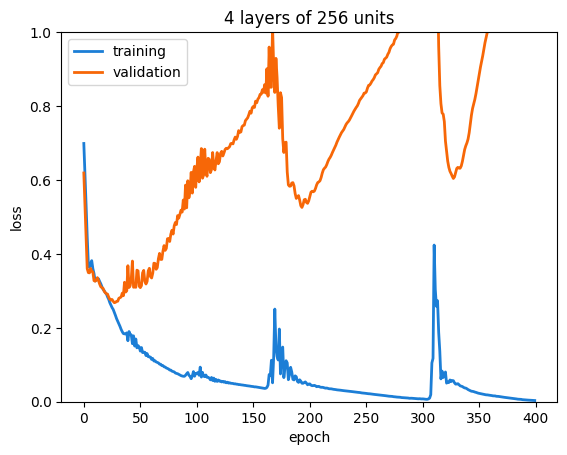

In [ ]:
plot_loss(history2, "4 layers of 256 units")

In [ ]:
keras.utils.set_random_seed(0)

model3 = keras.Sequential([
    keras.layers.Input(shape=(2,)),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid"),
])

history3 = train(model3)

Epoch 1/400
1/1 - 2s - 2s/step - accuracy: 0.3267 - loss: 0.7289 - val_accuracy: 0.3865 - val_loss: 0.7213
Epoch 2/400
1/1 - 0s - 115ms/step - accuracy: 0.4267 - loss: 0.7181 - val_accuracy: 0.4565 - val_loss: 0.7107
Epoch 3/400
1/1 - 0s - 110ms/step - accuracy: 0.4867 - loss: 0.7077 - val_accuracy: 0.4990 - val_loss: 0.7005
Epoch 4/400
1/1 - 0s - 118ms/step - accuracy: 0.5267 - loss: 0.6976 - val_accuracy: 0.5280 - val_loss: 0.6906
Epoch 5/400
1/1 - 0s - 113ms/step - accuracy: 0.5600 - loss: 0.6879 - val_accuracy: 0.5630 - val_loss: 0.6809
Epoch 6/400
1/1 - 0s - 124ms/step - accuracy: 0.5600 - loss: 0.6784 - val_accuracy: 0.5945 - val_loss: 0.6716
Epoch 7/400
1/1 - 0s - 132ms/step - accuracy: 0.5667 - loss: 0.6691 - val_accuracy: 0.6235 - val_loss: 0.6625
Epoch 8/400
1/1 - 0s - 113ms/step - accuracy: 0.6000 - loss: 0.6602 - val_accuracy: 0.6525 - val_loss: 0.6537
Epoch 9/400
1/1 - 0s - 111ms/step - accuracy: 0.6333 - loss: 0.6515 - val_accuracy: 0.6805 - val_loss: 0.6451
Epoch 10/400


In [ ]:
print("parameters", model3.count_params())

parameters 129


In [ ]:
# L1 and L2 Regularisation -> Reduce the weights with huge magnitude
# Dropout Regularisation -> Randomly turns off some neurons
# Early Stopping -> Stops the training midway if it feels it is going for overfit

In [ ]:
def train_long(model):
    model.compile(optimizer=keras.optimizers.Adam(0.003),
                  loss="binary_crossentropy",
                  metrics=["accuracy"])
    return model.fit(Xtr, ytr,
                     validation_data=(Xva, yva),
                     epochs=600, batch_size=150, verbose=2)

In [ ]:
keras.utils.set_random_seed(0)

model4 = keras.Sequential([
    keras.layers.Input(shape=(2,)),
    keras.layers.Dense(512, activation="relu"),
    keras.layers.Dense(512, activation="relu"),
    keras.layers.Dense(512, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid"),
])

history4 = train_long(model4)

Epoch 1/600
1/1 - 3s - 3s/step - accuracy: 0.6533 - loss: 0.6919 - val_accuracy: 0.8255 - val_loss: 0.5509
Epoch 2/600
1/1 - 0s - 105ms/step - accuracy: 0.8133 - loss: 0.5496 - val_accuracy: 0.8285 - val_loss: 0.4117
Epoch 3/600
1/1 - 0s - 101ms/step - accuracy: 0.8333 - loss: 0.4124 - val_accuracy: 0.8415 - val_loss: 0.3422
Epoch 4/600
1/1 - 0s - 103ms/step - accuracy: 0.8533 - loss: 0.3463 - val_accuracy: 0.8435 - val_loss: 0.3690
Epoch 5/600
1/1 - 0s - 105ms/step - accuracy: 0.8467 - loss: 0.3723 - val_accuracy: 0.8505 - val_loss: 0.3795
Epoch 6/600
1/1 - 0s - 98ms/step - accuracy: 0.8600 - loss: 0.3888 - val_accuracy: 0.8500 - val_loss: 0.3642
Epoch 7/600
1/1 - 0s - 103ms/step - accuracy: 0.8600 - loss: 0.3698 - val_accuracy: 0.8510 - val_loss: 0.3422
Epoch 8/600
1/1 - 0s - 109ms/step - accuracy: 0.8533 - loss: 0.3404 - val_accuracy: 0.8530 - val_loss: 0.3306
Epoch 9/600
1/1 - 0s - 104ms/step - accuracy: 0.8533 - loss: 0.3253 - val_accuracy: 0.8575 - val_loss: 0.3208
Epoch 10/600
1

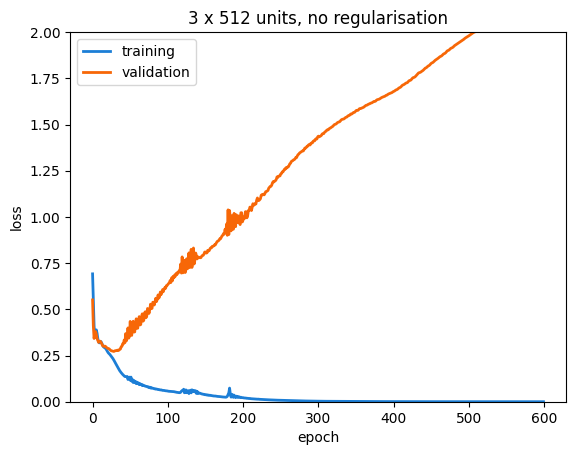

In [ ]:
plot_loss(history4, "3 x 512 units, no regularisation", ymax=2)

In [ ]:
keras.utils.set_random_seed(0)

model_l2 = keras.Sequential([
    keras.layers.Input(shape=(2,)),
    keras.layers.Dense(512, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-4)),
    keras.layers.Dense(512, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-4)),
    keras.layers.Dense(512, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-4)),
    keras.layers.Dense(1, activation="sigmoid"),
])

history_l2 = train_long(model_l2)

Epoch 1/600
1/1 - 3s - 3s/step - accuracy: 0.6533 - loss: 0.7945 - val_accuracy: 0.8250 - val_loss: 0.6514
Epoch 2/600
1/1 - 0s - 162ms/step - accuracy: 0.8133 - loss: 0.6501 - val_accuracy: 0.8285 - val_loss: 0.5105
Epoch 3/600
1/1 - 0s - 130ms/step - accuracy: 0.8333 - loss: 0.5112 - val_accuracy: 0.8410 - val_loss: 0.4378
Epoch 4/600
1/1 - 0s - 110ms/step - accuracy: 0.8533 - loss: 0.4418 - val_accuracy: 0.8435 - val_loss: 0.4596
Epoch 5/600
1/1 - 0s - 112ms/step - accuracy: 0.8467 - loss: 0.4629 - val_accuracy: 0.8495 - val_loss: 0.4677
Epoch 6/600
1/1 - 0s - 109ms/step - accuracy: 0.8600 - loss: 0.4765 - val_accuracy: 0.8500 - val_loss: 0.4512
Epoch 7/600
1/1 - 0s - 108ms/step - accuracy: 0.8600 - loss: 0.4568 - val_accuracy: 0.8515 - val_loss: 0.4264
Epoch 8/600
1/1 - 0s - 106ms/step - accuracy: 0.8533 - loss: 0.4252 - val_accuracy: 0.8535 - val_loss: 0.4126
Epoch 9/600
1/1 - 0s - 139ms/step - accuracy: 0.8533 - loss: 0.4079 - val_accuracy: 0.8570 - val_loss: 0.4014
Epoch 10/600


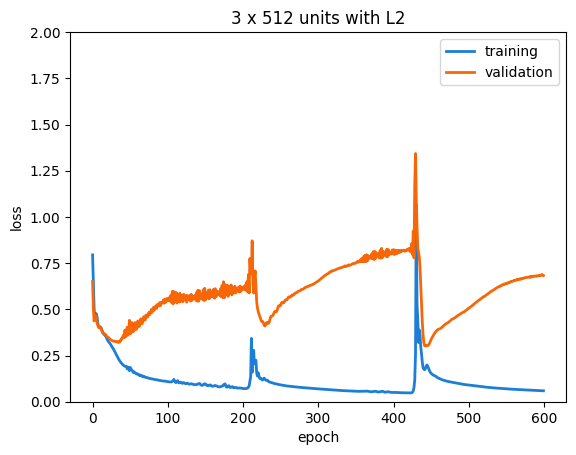

In [ ]:
plot_loss(history_l2, "3 x 512 units with L2", ymax=2)

In [ ]:
keras.utils.set_random_seed(0)

model_do = keras.Sequential([
    keras.layers.Input(shape=(2,)),
    keras.layers.Dense(512, activation="relu"),
    keras.layers.Dropout(0.7),
    keras.layers.Dense(512, activation="relu"),
    keras.layers.Dropout(0.7),
    keras.layers.Dense(512, activation="relu"),
    keras.layers.Dropout(0.7),
    keras.layers.Dense(1, activation="sigmoid"),
])

history_do = train_long(model_do)

Epoch 1/600
1/1 - 3s - 3s/step - accuracy: 0.5000 - loss: 0.7011 - val_accuracy: 0.7945 - val_loss: 0.6308
Epoch 2/600
1/1 - 0s - 122ms/step - accuracy: 0.7133 - loss: 0.6500 - val_accuracy: 0.8000 - val_loss: 0.5571
Epoch 3/600
1/1 - 0s - 109ms/step - accuracy: 0.7667 - loss: 0.5761 - val_accuracy: 0.8085 - val_loss: 0.4756
Epoch 4/600
1/1 - 0s - 110ms/step - accuracy: 0.8200 - loss: 0.5103 - val_accuracy: 0.8230 - val_loss: 0.4042
Epoch 5/600
1/1 - 0s - 106ms/step - accuracy: 0.8067 - loss: 0.4427 - val_accuracy: 0.8290 - val_loss: 0.3643
Epoch 6/600
1/1 - 0s - 120ms/step - accuracy: 0.8133 - loss: 0.4027 - val_accuracy: 0.8370 - val_loss: 0.3574
Epoch 7/600
1/1 - 0s - 107ms/step - accuracy: 0.8333 - loss: 0.3818 - val_accuracy: 0.8390 - val_loss: 0.3691
Epoch 8/600
1/1 - 0s - 112ms/step - accuracy: 0.8333 - loss: 0.4097 - val_accuracy: 0.8425 - val_loss: 0.3798
Epoch 9/600
1/1 - 0s - 108ms/step - accuracy: 0.8333 - loss: 0.3925 - val_accuracy: 0.8460 - val_loss: 0.3821
Epoch 10/600


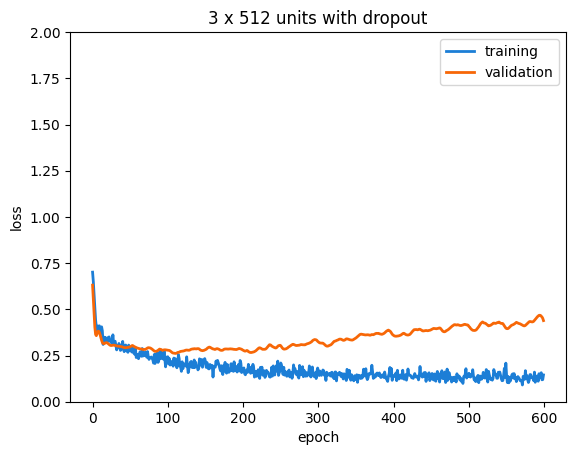

In [ ]:
plot_loss(history_do, "3 x 512 units with dropout", ymax=2)

In [ ]:
# Fill the Feedback